# PokéChallenge 2026 — comparison with two other teams

After the challenge we rebuilt the models of two other teams from their code and scored them on the same battles as ours. This document asks two questions:

1. How do the three teams compare when they are measured in the same way?
2. What can we say about the moves between the public and the private leaderboard?

| name here | team | public rank | private rank |
| --- | --- | --- | --- |
| ours | this repository: `compact_v5`, `v11`, `blend` | 2 | 1 |
| 2nd place | repository `FDS-Pokemon-Challenge-2026-2027` | 7 | 2 |
| 9th place | team predictive spikes, repository `predictive-spikes` | 1 | 9 |

The 9th place led the public leaderboard and fell to ninth on the private one: of the three teams it is the one that moved the most.

What is compared:

- **Ours and the 2nd place**: the three submissions of each team, with their public and private scores.
- **The 9th place**: the three final models listed in their README, rebuilt from the notebook they published on Kaggle: XGBoost on 140 features, XGBoost of depth 4, and the blend of four XGBoost models that the notebook writes as its submission. For this team we know only its best public score (71.866%) and its best private score (68.685%), not which files produced them.

The figures show one model per team: `blend` for us, the submission with the best private score for the 2nd place, and the blend of the 9th place.

What is measured and what is not:

- Sections 2 and 3 use only cross-validation on the 10,000 training battles, with every model rebuilt in this environment from its team's code.
- The public and private scores cannot be recomputed here, because the test labels are not available. They are the scores shown by Kaggle (ours and the 9th place's) or reported by the team (the 2nd place), and they are used only in section 4.

## 1. Setup

The notebook only reads the tables of `docs/evaluation/comparison/data/` and draws them (`draw.py`: pandas, numpy and matplotlib), so it runs in a few seconds and needs no competition data. The commands that produced the tables, which need the other teams' repositories and environments, are in the `README.md` next to this file.

- `REPOSITORY`: the project repository (pokechallenge-fall-2026)
- `REVISION = "main"`: the branch or tag that holds `docs/evaluation/comparison`

On Kaggle the repository is cloned (the notebook needs Internet access, in the notebook's settings) and the figures are saved in `/kaggle/working/figures`. In a local checkout the notebook uses the files next to it.

In [1]:
REPOSITORY = "https://github.com/CiottoloMaggico/pokechallenge-fall-2026.git"
REVISION = "main"  # the branch or tag that holds docs/evaluation/comparison

In [2]:
import os
import subprocess
from pathlib import Path

ON_KAGGLE = Path("/kaggle/working").exists()
if ON_KAGGLE:
    CLONE = Path("/kaggle/temp/pokechallenge")  # not saved with the notebook
    if not CLONE.exists():
        command = ["git", "clone", "--quiet", "--depth", "1", "--branch", REVISION]
        skip_lfs = {**os.environ, "GIT_LFS_SKIP_SMUDGE": "1"}  # the battles are not needed
        subprocess.run([*command, REPOSITORY, str(CLONE)], check=True, env=skip_lfs)
    os.chdir(CLONE)
elif not Path("main.py").exists():  # this file is docs/evaluation/comparison/comparison.ipynb
    os.chdir(Path.cwd().resolve().parents[2])
# every path below is relative to the repository's root

In [3]:
import sys

import pandas as pd

sys.path.insert(0, str(Path("docs/evaluation/comparison").resolve()))
import draw

%matplotlib inline
draw.apple_style()
DATA = Path("docs/evaluation/comparison/data")
FIGURES = Path("/kaggle/working/figures" if ON_KAGGLE else "docs/evaluation/comparison/figures")


def table(name):
    return pd.read_csv(DATA / f"{name}.csv")


oof, metrics, board = table("oof"), table("metrics"), table("leaderboard")

## 2. How the comparison was made

- **Same battles, same folds.** The 10,000 training battles are split in the 5 folds of our own evaluation (seed 33, duplicated battles kept together). Each model is fitted on four folds and predicts the fifth, so every battle is predicted once by a model that has not seen it.
- **Their code, not ours.** The 2nd place models are trained by their own training script, and the 9th place notebook (the one they ran on Kaggle) is run cell by cell. We only replaced the fold assignment.
- **The 9th place notebook is rerun once per fold**, with the four training folds as its training file and the fifth, without labels, as its test file. This matters because the notebook validates and predicts in two different ways:
  - *in its validation*, each XGBoost model is scored on a fold and also stops adding trees at the point where that same fold says it should (early stopping on the validation fold);
  - *for the test set*, it averages five models, each stopped on a fold of the training battles, so the test battles play no part in training.

  Rerunning the notebook predicts each of our folds the second way, as the test set was predicted. Section 4.2 measures the difference between the two.
- **Not rebuilt for the other teams:** the accuracy by last turn seen and the training loss, which are in our own evaluation. The figures below are the ones that could be drawn for all three teams.

Before comparing, we checked that the rebuilt models are the ones the teams describe:

| check | result |
| --- | --- |
| 2nd place, unit tests of their repository | 9 of 9 pass |
| 2nd place, accuracy with their own validation | 0.7106 and 0.7085, the values of their own rebuild on Kaggle |
| 2nd place, test predictions equal to the files they submitted | 4,964 and 4,922 of 5,000, the counts of their own rebuild on Kaggle |
| 9th place, unit tests of their repository | 7 of 7 pass |
| 9th place, accuracy, ROC AUC and log loss of their four models and of their blend, with their own validation | equal to the values printed in their Kaggle notebook (blend: 0.7009, 0.7761, 0.5642) |
| 9th place, test predictions of their blend | 2,596 wins of player 1 out of 5,000, as in their Kaggle notebook |

The README of the 9th place reports slightly higher values (0.7030 for the blend), from a run on another computer with other library versions. We follow their Kaggle notebook.

## 3. The three teams on the same folds

### 3.1 Performance

Accuracy and ROC AUC: higher is better. Log loss: lower is better. "± fold" is the standard deviation of the accuracy over the five folds.

In [4]:
draw.metrics_table(metrics, list(metrics["model"]))

Model,Accuracy,± fold,Log loss,ROC AUC
compact_v5,0.7184,0.0105,0.5407,0.7982
v11,0.7175,0.0047,0.5417,0.7979
blend,0.7232,0.0081,0.5355,0.8034
2nd: five views,0.7070,0.0129,0.5547,0.7860
2nd: five views + teams,0.7065,0.0122,0.5531,0.7867
2nd: tactical + teams,0.7084,0.0161,0.5546,0.7861
"9th: XGBoost, 140 features",0.6934,0.0093,0.5679,0.7725
"9th: XGBoost, depth 4",0.6889,0.0105,0.5710,0.7693
9th: blend of four XGBoost,0.6914,0.0078,0.5686,0.7718


The order is the same on the three metrics: our models first, then the 2nd place models, then the 9th place models. Taking one model per team, `blend` reaches 72.3% accuracy, the 2nd place 70.8% and the 9th place 69.1%. The team that led the public leaderboard has the lowest cross-validation of the three.

Inside each team the three models are close: at most 0.6 points of accuracy apart for us, 0.2 for the 2nd place and 0.5 for the 9th place. This is less than the fold-to-fold spread (0.5 to 1.6 points), so we do not rank the models of a team.

The blend of the 9th place is not better than its 140-feature member alone (69.1% against 69.3%, log loss 0.5686 against 0.5679). Its four members are the same kind of model (XGBoost) on overlapping feature sets, and the blend predicts the same winner as each of the two members in the table on about 98% of the battles. For comparison, `compact_v5` and `v11` agree on 88%, which is why averaging them helps.

The spread across folds is not small compared with the gaps between teams, so the table alone is not enough to say which gaps are real. The next table looks at that.

### 3.2 Differences fold by fold

For each pair of models we take the difference on each of the five folds. Two models are scored on the same battles, so part of the fold-to-fold variation cancels out in the difference. The p-value says how surprising the mean difference would be if the two models were equally good (the corrected test used everywhere in this repository, which takes into account that the folds share training battles). A small p means that the difference is larger than its variation across folds.

In [5]:
PAIRS = [
    ("blend", "second"),
    ("blend", "spikes"),
    ("second", "spikes"),
    ("compact_v5", "second"),
    ("v11", "second"),
    ("compact_v5", "spikes"),
    ("v11", "spikes"),
]
draw.paired_table(table("paired"), PAIRS)

Comparison,Δ accuracy (points),p,Δ log loss,p,Δ ROC AUC,p
blend − 2nd: tactical + teams,+1.48,0.130,-0.0191,0.003,+0.0174,0.005
blend − 9th: blend of four XGBoost,+3.18,0.010,-0.0331,0.001,+0.0317,0.003
2nd: tactical + teams − 9th: blend of four XGBoost,+1.70,0.156,-0.0139,0.039,+0.0143,0.060
compact_v5 − 2nd: tactical + teams,+1.00,0.079,-0.0139,0.012,+0.0121,0.013
v11 − 2nd: tactical + teams,+0.91,0.326,-0.0130,0.022,+0.0118,0.034
compact_v5 − 9th: blend of four XGBoost,+2.70,0.026,-0.0278,0.004,+0.0264,0.008
v11 − 9th: blend of four XGBoost,+2.61,0.010,-0.0269,0.003,+0.0261,0.005


- **`blend` and the 2nd place.** `blend` is 1.5 points higher in accuracy, but with p = 0.13 we cannot say that this gap is real. For log loss (−0.019, p = 0.003) and ROC AUC (+0.017, p = 0.005) the difference is clear: the probabilities of `blend` are better, even if the count of right answers does not separate the two with five folds.
- **`blend` and the 9th place.** The gap is 3.2 points of accuracy (p = 0.010), 0.033 of log loss (p = 0.001) and 0.032 of ROC AUC (p = 0.003). It is clear on all three metrics and it is the largest gap of the table.
- **Our single models.** `compact_v5` and `v11` are each about 1 point above the 2nd place in accuracy (p = 0.08 and 0.33, so not established) and better in log loss and ROC AUC (p between 0.01 and 0.03). Against the 9th place they are 2.7 and 2.6 points above (p = 0.03 and 0.01), and better in log loss and ROC AUC with p below 0.01.
- **2nd place and 9th place.** 1.7 points of accuracy (p = 0.16); the difference in log loss and ROC AUC is at the limit (p = 0.04 and 0.06).

Two cautions. There are five folds and one fold assignment, so the test is weak, and the table holds 21 comparisons, so a p around 0.03 is weaker evidence than it looks. And every team chose its features and settings on these same 10,000 battles, which tends to make cross-validation numbers a little too good; we cannot measure by how much for each team.

### 3.3 ROC curves

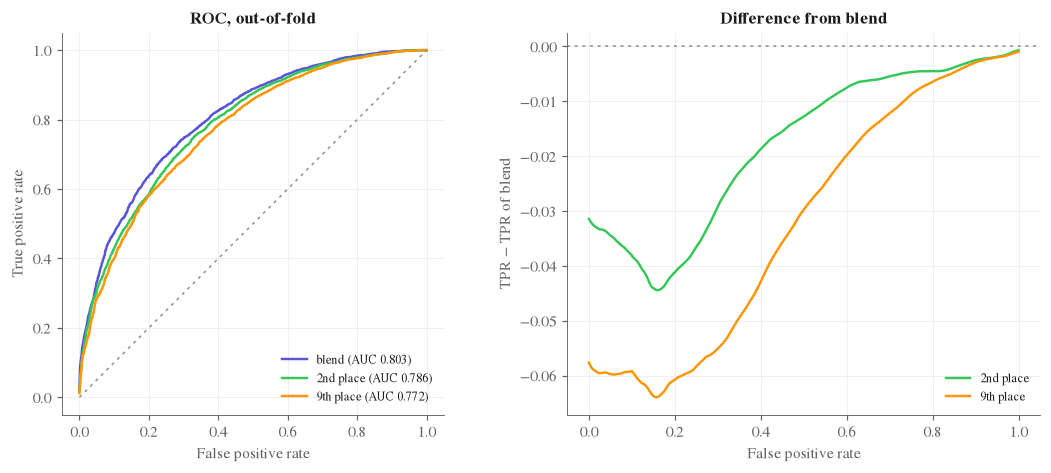

In [6]:
draw.plot_roc(oof, metrics, FIGURES);

The left panel shows one ROC curve per team, built from the 10,000 out-of-fold probabilities. The AUC values (0.803, 0.786, 0.772) are those of the table. The right panel plots the true positive rate of the other two teams minus that of `blend`, at each false positive rate.

Both lines are below zero everywhere: at every false positive rate `blend` finds at least as many of the real wins of player 1. The gap is largest on the left, at low false positive rates: about 6 points for the 9th place from 0 to 0.2, and about 4 points for the 2nd place around 0.15. The left part of the curve is made of the battles that each model ranks as the most likely wins of player 1, so this is where `blend` gains the most. Towards the right every curve must reach 1, so the gaps close there by construction. These curves come from one run and have no confidence band.

### 3.4 Accuracy vs confidence

The confidence of a prediction is the probability the model gives to the winner it predicts, max(p, 1 − p). For each threshold t, the top panel shows the accuracy on the battles with confidence of at least t, and the bottom panel shows the share of battles that are left.

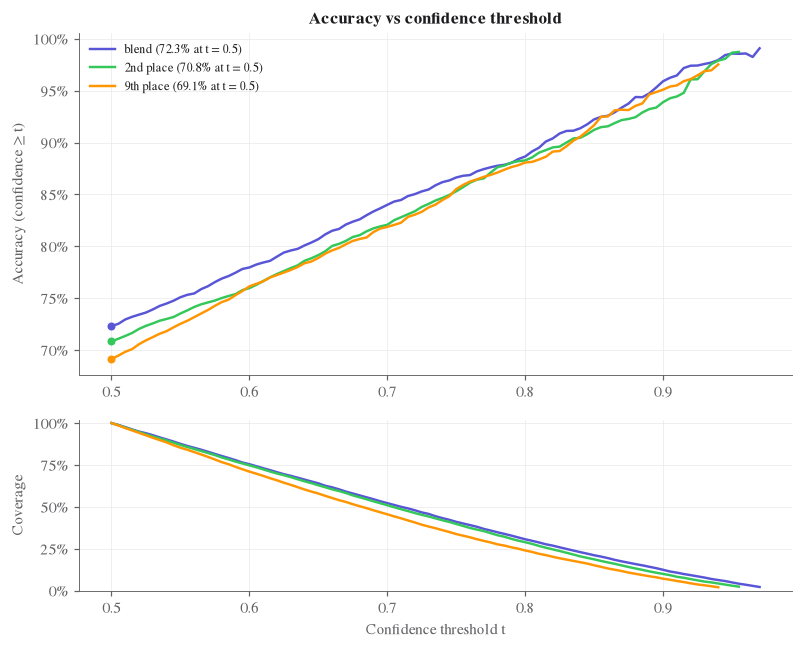

In [7]:
draw.plot_confidence(oof, DATA, FIGURES);

For all three teams accuracy grows steadily with confidence, so a high probability does mean a safer prediction.

| battles kept | `blend` | 2nd place | 9th place |
| --- | --- | --- | --- |
| confidence ≥ 0.7: share kept, accuracy | 52%, 84.0% | 51%, 82.1% | 46%, 81.9% |
| confidence ≥ 0.9: share kept, accuracy | 12%, 95.9% | 10%, 93.9% | 7%, 95.1% |

`blend` is above the other two up to a threshold of about 0.85 and keeps more battles at the same threshold. The 9th place starts lowest (69.1% on all the battles), reaches the 2nd place at about 0.6 and is slightly above it beyond 0.85. It is also confident less often: its coverage line is the lowest, with 46% of the battles above 0.7. Beyond 0.9 fewer than 1,300 battles remain and the lines are noisy.

### 3.5 Calibration

Calibration asks whether a probability can be taken at face value: among the battles to which a model gives about 70% for player 1, does player 1 win about 70% of them? A calibrated model lies on the diagonal. The bars show how many battles fall in each bin, and the ECE in the legend is the average distance from the diagonal.

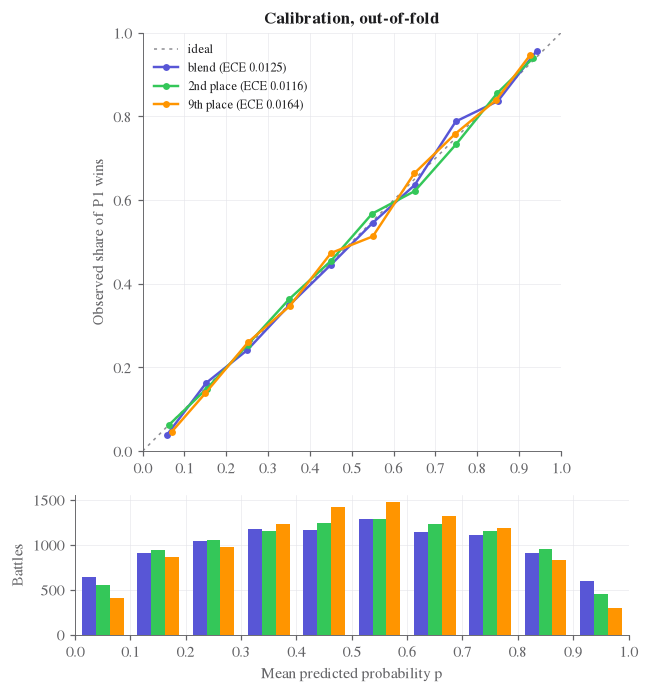

In [8]:
draw.plot_calibration(oof, DATA, FIGURES);

`blend` and the 2nd place are close to the diagonal (ECE 0.0125 and 0.0116), and their differences are of the size of the noise in a bin (about 1.3 points with 1,500 battles).

The 9th place is a little further from it (ECE 0.0164). The difference comes from the two middle bins: the battles to which it gives about 55% are won by player 1 51% of the time (1,477 battles, a gap of 3.7 points, almost three times the noise of a bin), and those at about 45% are won 47% of the time. Elsewhere it lies on the diagonal. One bin out of ten that far from the diagonal could still be chance, so we only note it.

The bars show a clearer difference. The 9th place model gives a probability between 0.4 and 0.6 to 29% of the battles (25% for the other two), and below 0.1 or above 0.9 to only 713 battles, against 998 for the 2nd place and 1,245 for `blend`. Its probabilities stay closer to 0.5, in line with its lower ROC AUC: it separates wins from losses less sharply. Having many battles near 0.5 also makes its accuracy sensitive to small changes of the model, because those battles cross the threshold easily (section 4.2).

### 3.6 Agreement between the teams

For each of the other two teams, we split the 10,000 battles into those on which its model and `blend` predict the same winner and those on which they predict different winners. Each bar is the accuracy of one model on one group, with an interval computed over battles.

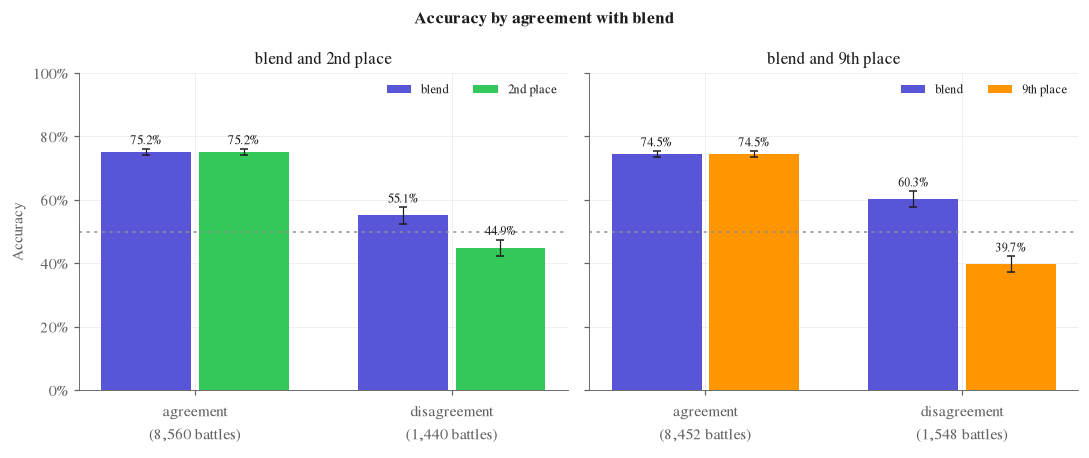

In [9]:
draw.plot_disagreement(draw.disagreement_table(oof, DATA), FIGURES);

`blend` and the 2nd place predict the same winner on 8,560 battles (85.6%), and both are right on 75.2% of them. They disagree on 1,440 battles (14.4%). There exactly one of the two is right, so the two bars add up to 100%: `blend` is right 55.1% of the time (interval 52.5% to 57.7%) and the 2nd place 44.9%.

With the 9th place the agreement is a little lower, 84.5% of the battles, and on the other 1,548 `blend` is right 60.3% of the time (57.8% to 62.8%), the widest margin of the two.

For reference, `compact_v5` and `v11` agree on 88.3% of the battles. So the models of three teams, built independently, make the same call on about 85 battles out of 100. The whole gap in accuracy comes from the other 15, and on those `blend` is right more often than the other model, but far from always.

On the test set, where there are no labels, we can still count agreement: 85.8% with the 2nd place and 85.3% with the 9th place (`agreement.csv`), about the same as on the training battles. So on the test battles the 9th place model does not disagree with ours more often than in cross-validation, which matters for section 4.

### 3.7 Validation log loss by training size

For one validation fold (2,000 battles) each model is refitted from scratch on the first n of the other 8,000 battles, the same battles for the three teams. The 2nd place line is their main model without its last step (a small logistic regression that cannot be refitted in this experiment). The 9th place line is their whole notebook, so at each size its prediction is the mean of five models trained on four fifths of the n battles. `blend` has a point every 250 battles, the other two at 500 and every 1,000.

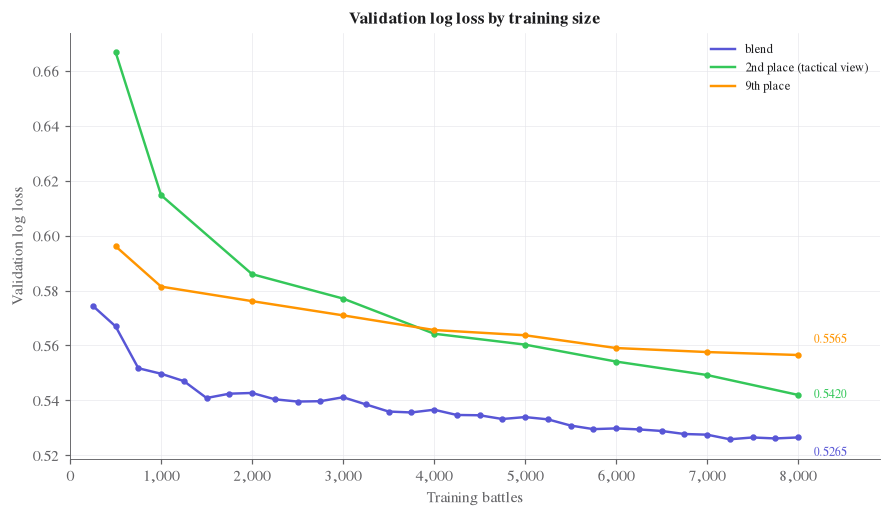

In [10]:
draw.plot_loss_convergence(table("loss_curve"), FIGURES);

`blend` is the lowest line at every size. With 500 battles it is at 0.567, against 0.596 for the 9th place and 0.667 for the 2nd place. With 8,000 the values are 0.527, 0.557 and 0.542.

The two other teams behave differently. The 2nd place model gains the most from data (from 0.667 to 0.542) and is still going down at 8,000 battles. The 9th place model is better than the 2nd place with little data, but gains little after 4,000 battles (0.566 to 0.557), and the 2nd place passes it there. From 1,000 to 8,000 battles the 9th place stays about 0.03 above `blend`: in this range more training battles do not narrow the gap.

The curves come from a single fold, so differences of a few thousandths are within noise.

## 4. Public and private leaderboard

The test file has 5,000 battles. The public leaderboard uses 1,500 of them (30%) and the private one the other 3,500 (70%). The scores below are the ones shown by Kaggle for our submissions and for the 9th place, and the ones the 2nd place reports in its repository (`data/leaderboard.csv`).

For the 9th place there is a single row: its best public score and its best private score. They may come from two different files, and we do not know whether these files are among the models we rebuilt. Kaggle's public leaderboard shows the best public score of all the files a team sent during the challenge, not only of its final ones. To place the row we use the cross-validation of their blend; their other two rebuilt models are 0.2 points above and below it (69.3% and 68.9%).

### 4.1 Cross-validation, public and private scores

Each row is a submission (for the 9th place, the team's best scores). The diamond is the accuracy in cross-validation on our folds (section 3.1), the empty circle the public score and the full circle the private score.

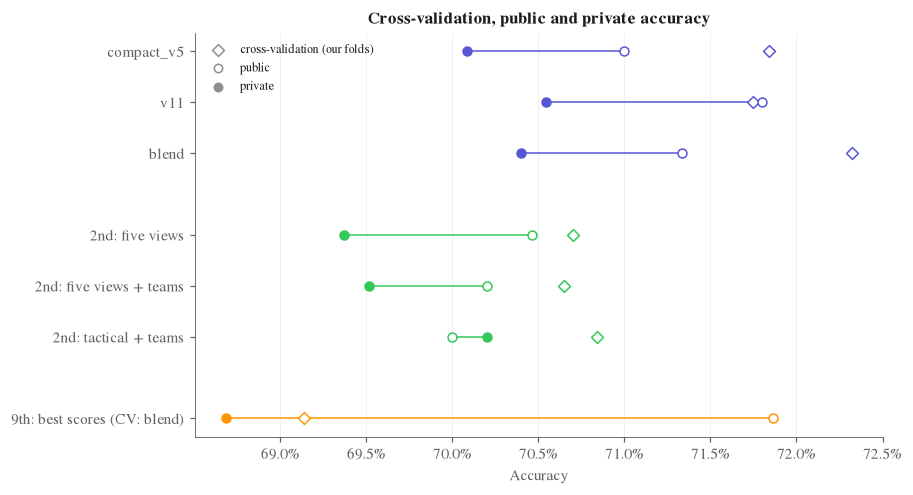

In [11]:
draw.plot_leaderboard(board, metrics, FIGURES);

In [12]:
draw.leaderboard_table(board, metrics)

Team,Submission,Cross-validation,Public,Private,Private − public (points)
ours,compact_v5,0.7184,0.7100,0.7008,-0.91
ours,v11,0.7175,0.7180,0.7054,-1.26
ours,blend,0.7232,0.7133,0.7040,-0.93
2nd place,2nd: five views,0.7070,0.7047,0.6937,-1.09
2nd place,2nd: five views + teams,0.7065,0.7020,0.6951,-0.69
2nd place,2nd: tactical + teams,0.7084,0.7000,0.7020,+0.20
9th place,9th: best scores (CV: blend),0.6914,0.7187,0.6868,-3.18


- **Every private score is below its cross-validation value**: by 1.2 to 1.9 points for ours, 0.6 to 1.3 for the 2nd place, and for the best private score of the 9th place 0.5 points below their blend (68.7% against 69.1%; 0.2 to 0.7 against their other two rebuilt models). The drop is common to the three teams. The data cannot tell where the common drop comes from: cross-validation numbers that are a little too good, test battles that differ slightly from the training ones, or both.
- **The private order of the teams is the order of the cross-validation**: ours, 2nd place, 9th place.
- **The public order is not.** The best public score of the 9th place (71.866%) is above our best one (`v11`, 71.800%) by one battle out of 1,500, although its cross-validation is 2.6 points below `v11` and 1.7 points below the 2nd place.
- **The public scores sit differently around the cross-validation values**: ours are from 1.0 point below to equal, those of the 2nd place 0.2 to 0.8 below, while the best public score of the 9th place is 2.7 points above.
- Inside a team the two leaderboards do not agree on the best submission. For the 2nd place the best private score belongs to the lowest public score. For us `v11` is the best on both, while `blend`, the best in cross-validation, is between our two other submissions on both. These differences between submissions of one team are fractions of a point.

### 4.2 Was any team misled by its own validation?

A team could fall on the private leaderboard because its own validation was too optimistic. The table shows the accuracy of each model measured in three ways:

- **own validation**: the team's own procedure, with its own folds;
- **our folds**: the same procedure, run on our folds;
- **our folds, refitted**: each of our folds predicted the way the test set was, with everything fitted on the other four folds only (the values of section 3).

For us and the 2nd place the second and third columns are the same procedure.

In [13]:
draw.estimates_table(table("estimates"))

Model,own validation,our folds,"our folds, refitted"
blend,0.7232,0.7232,0.7232
2nd: tactical + teams,0.7072,0.7084,0.7084
9th: blend of four XGBoost,0.7009,0.6978,0.6914
"9th: XGBoost, 140 features",0.6998,0.6968,0.6934
"9th: XGBoost, depth 4",0.6991,0.6949,0.6889


For us and the 2nd place the three columns are close: the 2nd place measured 70.7% and we find 70.8%.

The 9th place is the one team whose own validation is clearly too optimistic. For their blend they measured 70.1%; on our folds, with their procedure, we find 69.8%; predicting each fold the way their notebook predicts the test set, 69.1%.

- **First to second column (−0.3 points):** only the fold assignment changes. This is within fold noise.
- **Second to third column (−0.6 points):** same folds, same models, only the procedure changes. The drop appears on four folds of five (p = 0.07; for their depth-4 model it is 0.6 points on all five folds, p = 0.002). The log loss is the same under the two procedures (0.5673 and 0.5686) and the 360 battles that change side all have probabilities between 0.39 and 0.61 (87% between 0.45 and 0.55). So the lost accuracy comes from the battles near 0.5, of which this model has many (section 3.5), and not from probabilities that are worse overall.

Two things change between the second and the third column. In their validation each model stops on the fold it is scored on, and it is trained on 8,000 battles instead of being the mean of five models trained on 6,400. Our runs do not separate the two effects. Either way, the third column is how their notebook predicts the test set, so about 69.1% is what their own validation should have reported for it, not 70.1%. Their feature subsets and model settings were also chosen on all 10,000 battles (their `train.py`); we did not redo that choice inside our folds, so all three columns may still flatter them a little.

So the 9th place expected about one point more than its models give. That point is small next to the gaps between teams (1.7 points to the 2nd place, 3.2 to us) and it does not explain the fall: their best private score is close to the 69.1% of the third column. The number that does not fit is the public one.

### 4.3 How much can a score move by chance?

We do not have the test labels, so we use the training battles as a stand-in. We draw 5,000 of them at random, call the first 1,500 "public" and the other 3,500 "private", and compute the accuracy of the out-of-fold predictions on each part. We repeat this 5,000 times. The histogram shows private minus public accuracy for `blend`; for the other models it is nearly the same (standard deviation 1.4 for each). The triangles are the real differences: for us and the 2nd place one per submission, for the 9th place its best private minus its best public score.

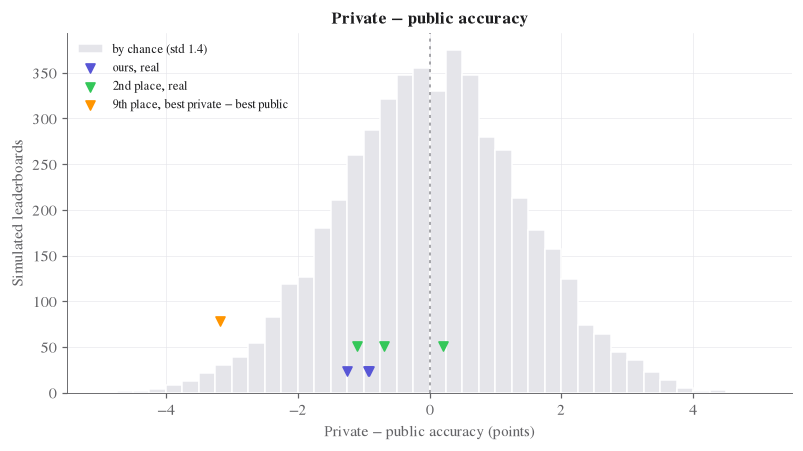

In [14]:
draw.plot_swing(table("split_simulation"), board, FIGURES);

By chance alone, the private score of a model differs from its public score with a standard deviation of 1.4 points, the same for the three teams. This is just the noise of measuring an accuracy near 70% on 1,500 and on 3,500 battles: a model does not need to change for its score to move by a point or two.

The moves of ours and of the 2nd place are inside this range: −0.9, −1.3 and −0.9 points for ours, +0.2, −0.7 and −1.1 for the 2nd place. A move of at least 0.9 points in either direction happens in about half of the simulated leaderboards.

For the 9th place the triangle is at −3.2 points, and one thing is certain even without knowing the files: the file that scored 71.866% on the public part scored at most 68.685% on the private part, so it lost at least 3.2 points. The simulation gives such a loss in 1.5% of the leaderboards for their blend. Looked at one part at a time, assuming their files behave like the models we rebuilt:

- **The private score is ordinary.** 68.685% or less happens in 23% of the simulated leaderboards for their blend.
- **The public score is not.** 71.866% or more happens in 0.7% of them, and in 1.2% if each time we keep the best of the three models we rebuilt; they agree so much that choosing the best one gains only 0.3 points on average. Moreover their blend is ahead of `blend` on the same public battles in only 0.06% of the simulated leaderboards, while on the real public part the 9th place was ahead of all our submissions.

So in the simulation the 9th place's rank comes from an unusually high public score, not from an unusually low private one. The data cannot say why its public score was so high. Two facts make it less surprising than the 0.7% suggests: Kaggle shows the best public score over every file a team sent, which may include files unlike the models we rebuilt; and the team at the top of a public leaderboard of many teams is, by being at the top, likely to be one whose public draw was favourable.

Our own submissions lost about one point, like those of the 2nd place. The real scores give no sign that our models move less than theirs between the two parts.

Three things limit this reading:

- The moves are not independent facts. All the submissions are measured on the same split of the same test battles and mostly make the same predictions, so if the public battles happen to be a little easier, every score drops together. In the simulation the moves of two teams go together (correlation about 0.6), and the three teams move in the same direction in 58% of the simulated leaderboards.
- The simulation uses training battles and assumes that each model is worth on the test set what it is worth in cross-validation. It cannot explain why all the private scores are below the cross-validation values (section 4.1).
- For the 9th place we do not know which files were scored, so the comparison rests on the models rebuilt from their notebook.

### 4.4 Gaps between teams

A rank depends on the gap between two teams, not on one score. Two teams are scored on the same battles and agree on most of them, so the gap moves less than a single score. The table shows, for each team's best private submission (for us `v11`, for the 9th place its best scores), the gap in cross-validation and on the two leaderboards, in points of accuracy. "± chance" is the standard deviation of such a gap over the simulated leaderboards.

In [15]:
draw.gap_table(board, metrics, table("split_simulation"))

Gap,Cross-validation,Public,± chance,Private,± chance
v11 − 2nd: tactical + teams,+0.91,+1.80,0.9,+0.34,0.5
v11 − 9th: best scores (CV: blend),+2.61,-0.07,0.9,+1.86,0.5
2nd: tactical + teams − 9th: best scores (CV: blend),+1.70,-1.87,1.0,+1.51,0.5


- **By chance a gap moves by about 0.9 points on the public part and 0.5 on the private part.** On 1,500 battles, teams that are less than a point or two apart can easily swap places.
- **Ours and the 9th place.** In cross-validation `v11` is 2.6 points above their blend. On the private part the gap is 1.9 points, about one and a half chance values below the cross-validation. On the public part it is −0.1: almost three chance values away.
- **2nd place and 9th place.** In cross-validation 1.7 points. On the private part 1.5, as in cross-validation. On the public part −1.9: almost four chance values away.
- **Ours and the 2nd place.** The gap is 1.8 points on the public part and 0.3 on the private part, on the two sides of the 0.9 of the cross-validation and each about one chance value away from it. The private gap is about 12 battles out of 3,500 and smaller than the chance value: the private leaderboard alone does not separate the first two places. The cross-validation is in our favour (section 3.2), clearly for log loss and ROC AUC and not clearly for accuracy.

So on the private part every gap is within about one and a half chance values of the cross-validation, while the two public gaps involving the 9th place are three to four chance values away. Since the 9th place's public and private scores may come from different files, and the cross-validation of their other two models differs from their blend's by 0.2 points, these distances are approximate.

One more caution about our own models: `compact_v5` scored 70.1% on the private part, just below the best 2nd place submission (70.2%), although it is 1.0 point above it in cross-validation. A change of this size is about twice the chance value. It agrees with the remark of our evaluation that the numbers of `compact_v5` may be a little optimistic, because its features and hyper-parameters were selected on the training battles. One case is not enough to establish it.

## 5. Conclusions

- Measured on the same folds, the order of the teams is ours, 2nd place, 9th place, on accuracy, log loss and ROC AUC. The team that led the public leaderboard has the lowest cross-validation of the three.
- Against the 9th place the gap is clear (3.2 points of accuracy for `blend`, p = 0.01). Against the 2nd place `blend` has better probabilities (log loss and ROC AUC), while the 1.5 points of accuracy cannot be separated from noise with five folds.
- `blend` and the 2nd place are equally well calibrated. The 9th place keeps its probabilities closer to 0.5, in line with its lower ROC AUC. The gap between the teams is largest among the battles each model ranks as the most likely wins of player 1.
- The models of the three teams predict the same winner on about 85% of the battles, on the training and on the test set. The gap in accuracy comes from the other 15%, where `blend` is right 55% (against the 2nd place) and 60% (against the 9th place) of the time.
- In the one fold we tested, `blend` has the lowest log loss at every training size, and its gap to the 9th place stays about 0.03 from 1,000 to 8,000 battles.
- The private leaderboard puts the three teams in the order of the cross-validation. The public one does not: the 9th place was first, one battle ahead of our best public score.
- The 9th place's own validation was about one point too optimistic (70.1% against 69.1% for their blend), because it validates differently from how it predicts the test set (each model stopped on the fold it is scored on, one model on 8,000 battles instead of the mean of five on 6,400). For us and the 2nd place the team's own estimate is close to ours.
- By chance alone a score moves by about 1.4 points between the public and the private part. Our moves and those of the 2nd place are inside that range. The 9th place's best public file lost at least 3.2 points. Taking the rebuilt models as a guide, their best private score (68.7%) is an ordinary draw, while their best public score (71.9%) happens in about 1 of 100 simulated leaderboards. In that sense their fall from first to ninth comes from the public score, not from the private one. The data cannot say why the public score was so high.
- About our own stability: our scores dropped by about one point from the public to the private part, like those of the 2nd place, and the simulation gives no reason to think that our models move less. Our gap over the 9th place on the private part (1.9 points) is more than three times the noise. Our gap over the 2nd place on the private part (0.3 points) is not larger than the noise.

Limits: one fold assignment with five folds; cross-validation numbers that may be a little optimistic for every team; leaderboard scores taken from Kaggle and from the 2nd place's repository, not reproduced; for the 9th place only the best public and best private scores, from files we do not know; a simulation made on training battles, not on the test set.